# House Price Prediction Using Linear Regression

## Project Introduction

The objective of this project is to develop a Machine Learning model
that predicts house prices based on different property features.

## Dataset Information

The dataset contains information about 180 houses.

## Features

- Area
- Bedrooms
- Bathrooms
- House age
- Location score
- Parking spaces

## Target Variable

House price in million PKR.

## Machine Learning Algorithm

Linear Regression.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [5]:
np.random.seed(42)

number_of_houses = 180

area = np.random.randint(650, 4200, number_of_houses)

In [6]:
print("Number of houses:", len(area))
print("First 10 house areas:", area[:10])
print("Minimum area:", area.min())
print("Maximum area:", area.max())

Number of houses: 180
First 10 house areas: [3824 4157 1510 1944 1780 1745 3742 2288 2819 1116]
Minimum area: 671
Maximum area: 4197


In [7]:
bedrooms = np.clip(
    np.round(area / 650 + np.random.normal(0, 0.8, number_of_houses)),
    1, 6
).astype(int)

bathrooms = np.clip(
    np.round(bedrooms * 0.65 + np.random.normal(0, 0.5, number_of_houses)),
    1, 5
).astype(int)

house_age = np.random.randint(0, 35, number_of_houses)

location_score = np.random.randint(1, 11, number_of_houses)

parking_spaces = np.random.randint(0, 3, number_of_houses)

In [8]:
price = (
    4.0
    + area * 0.012
    + bedrooms * 1.1
    + bathrooms * 0.8
    - house_age * 0.09
    + location_score * 1.7
    + parking_spaces * 0.55
    + np.random.normal(0, 3.2, number_of_houses)
)

price = np.maximum(price, 8).round(2)

In [9]:
df = pd.DataFrame({
    "area_sqft": area,
    "bedrooms": bedrooms,
    "bathrooms": bathrooms,
    "house_age_years": house_age,
    "location_score": location_score,
    "parking_spaces": parking_spaces,
    "price_million_pkr": price
})

In [10]:
import os

print("Current working directory:")
print(os.getcwd())

Current working directory:
C:\Users\Rania


In [11]:
import os

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("Project folders are ready!")

Project folders are ready!


In [12]:
df.to_csv("data/house_prices.csv", index=False)

print("Dataset created successfully!")

Dataset created successfully!


In [13]:
print(os.path.exists("data/house_prices.csv"))

True


In [14]:
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (180, 7)
   area_sqft  bedrooms  bathrooms  house_age_years  location_score  \
0       3824         6          4               10               3   
1       4157         6          4               33               1   
2       1510         1          1               33               8   
3       1944         3          2               17               6   
4       1780         3          2               29               8   

   parking_spaces  price_million_pkr  
0               2              73.18  
1               1              62.66  
2               1              38.88  
3               1              39.20  
4               0              41.14  


In [15]:
print("Dataset shape:", df.shape)
print("Dataset saved successfully!")

Dataset shape: (180, 7)
Dataset saved successfully!


In [16]:
print(df.shape)
print(df.head())
print(df.columns)

(180, 7)
   area_sqft  bedrooms  bathrooms  house_age_years  location_score  \
0       3824         6          4               10               3   
1       4157         6          4               33               1   
2       1510         1          1               33               8   
3       1944         3          2               17               6   
4       1780         3          2               29               8   

   parking_spaces  price_million_pkr  
0               2              73.18  
1               1              62.66  
2               1              38.88  
3               1              39.20  
4               0              41.14  
Index(['area_sqft', 'bedrooms', 'bathrooms', 'house_age_years',
       'location_score', 'parking_spaces', 'price_million_pkr'],
      dtype='object')


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   area_sqft          180 non-null    int32  
 1   bedrooms           180 non-null    int64  
 2   bathrooms          180 non-null    int64  
 3   house_age_years    180 non-null    int32  
 4   location_score     180 non-null    int32  
 5   parking_spaces     180 non-null    int32  
 6   price_million_pkr  180 non-null    float64
dtypes: float64(1), int32(4), int64(2)
memory usage: 7.2 KB


In [18]:
print(df.isnull().sum())

area_sqft            0
bedrooms             0
bathrooms            0
house_age_years      0
location_score       0
parking_spaces       0
price_million_pkr    0
dtype: int64


In [19]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [20]:
df.describe()

,area_sqft,bedrooms,bathrooms,house_age_years,location_score,parking_spaces,price_million_pkr
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,2467.638889,3.738889,2.505556,16.322222,5.505556,1.033333,48.785944
std,1016.635088,1.702328,1.179420,10.217553,2.854962,0.804318,15.665504
min,671.000000,1.000000,1.000000,0.000000,1.000000,0.000000,14.560000
25%,1621.250000,2.000000,1.750000,7.750000,3.000000,0.000000,36.120000
50%,2522.000000,4.000000,2.000000,16.000000,6.000000,1.000000,48.185000
75%,3387.250000,5.000000,3.250000,25.000000,8.000000,2.000000,62.045000
max,4197.000000,6.000000,5.000000,34.000000,10.000000,2.000000,84.070000


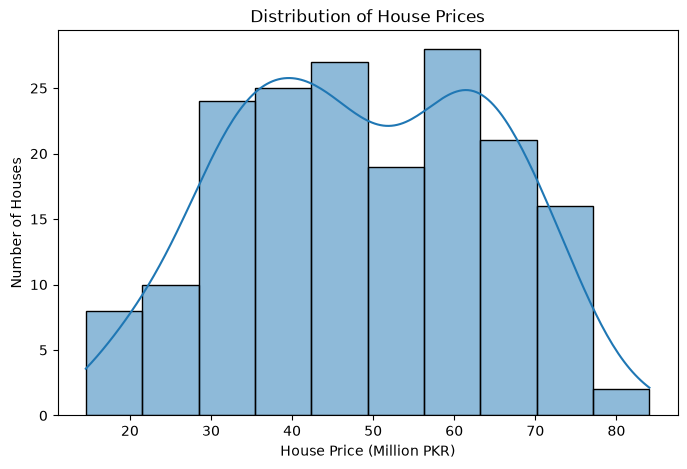

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["price_million_pkr"],
    bins=10,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("House Price (Million PKR)")
plt.ylabel("Number of Houses")

plt.show()

In [29]:
X = df[
    [
        "area_sqft",
        "bedrooms",
        "bathrooms",
        "house_age_years",
        "location_score",
        "parking_spaces"
    ]
]

y = df["price_million_pkr"]

In [30]:
print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Features (X):
   area_sqft  bedrooms  bathrooms  house_age_years  location_score  \
0       3824         6          4               10               3   
1       4157         6          4               33               1   
2       1510         1          1               33               8   
3       1944         3          2               17               6   
4       1780         3          2               29               8   

   parking_spaces  
0               2  
1               1  
2               1  
3               1  
4               0  

Target (y):
0    73.18
1    62.66
2    38.88
3    39.20
4    41.14
Name: price_million_pkr, dtype: float64

Shape of X: (180, 6)
Shape of y: (180,)


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [32]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (144, 6)
Testing features: (36, 6)
Training target: (144,)
Testing target: (36,)


In [33]:
model = LinearRegression()

In [34]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [35]:
print("Model Intercept:")
print(model.intercept_)

print("\nModel Coefficients:")
print(model.coef_)

Model Intercept:
5.072257529684194

Model Coefficients:
[ 0.01177065  1.35398953  0.71829995 -0.0869769   1.65166737  0.24514831]


In [36]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred)

Predictions:
[75.57196283 34.27428497 63.487066   55.54008163 71.81827089 78.2642318
 59.00905395 69.66223648 25.60228259 25.77576297 23.21693747 30.53267431
 46.7779507  27.59936921 66.3133231  70.3339103  70.17272487 75.63270431
 43.13109857 61.60792406 54.32387292 37.2661302  67.01897791 29.64085683
 28.38274446 35.55756937 29.78605749 50.73098429 46.81288189 59.09522867
 26.63918228 42.94401476 20.35079949 48.36249063 76.5451206  30.92321546]


In [37]:
print("Number of predictions:", len(y_pred))

Number of predictions: 36


In [38]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison["Difference"] = (
    comparison["Actual Price"] -
    comparison["Predicted Price"]
)

print(comparison.head(10))

   Actual Price  Predicted Price  Difference
0         70.60        75.571963   -4.971963
1         31.77        34.274285   -2.504285
2         63.09        63.487066   -0.397066
3         54.46        55.540082   -1.080082
4         73.66        71.818271    1.841729
5         76.94        78.264232   -1.324232
6         60.85        59.009054    1.840946
7         64.18        69.662236   -5.482236
8         30.52        25.602283    4.917717
9         33.13        25.775763    7.354237


In [39]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 2.2178034941028204


In [40]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 8.312862839092984


In [41]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 2.8832035722600278


In [42]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.9737230547588656


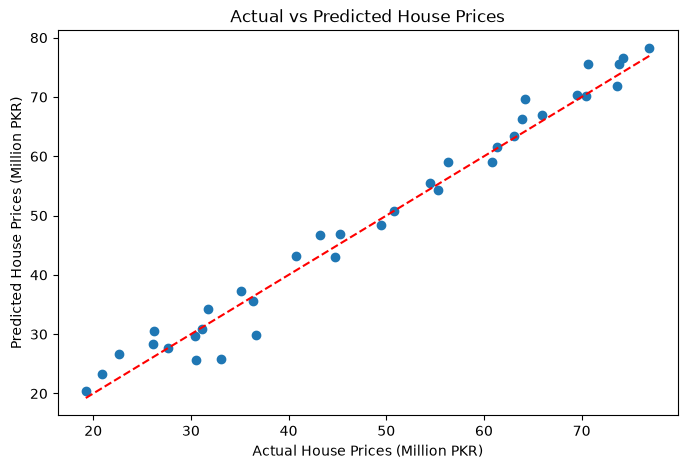

In [43]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Prices (Million PKR)")
plt.ylabel("Predicted House Prices (Million PKR)")
plt.title("Actual vs Predicted House Prices")

plt.show()

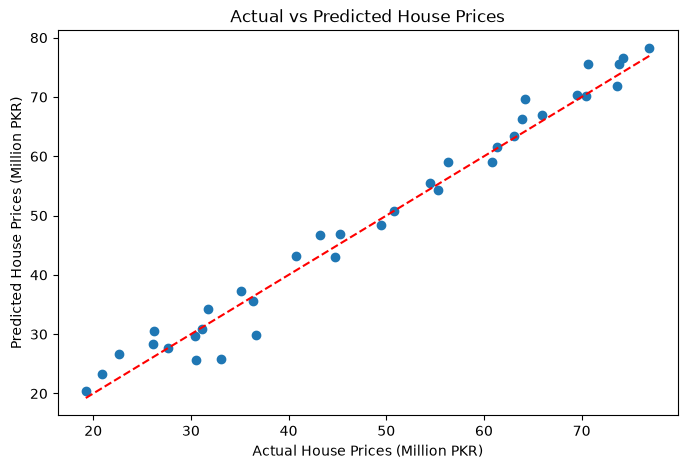

Graph saved successfully!


In [44]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Prices (Million PKR)")
plt.ylabel("Predicted House Prices (Million PKR)")
plt.title("Actual vs Predicted House Prices")

plt.savefig(
    "figures/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")

In [45]:
import os

print(os.path.exists("figures/actual_vs_predicted.png"))

True


In [46]:
evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Value": [mae, mse, rmse, r2]
})

print(evaluation_results)

     Metric     Value
0       MAE  2.217803
1       MSE  8.312863
2      RMSE  2.883204
3  R2 Score  0.973723


In [47]:
evaluation_results.to_csv(
    "outputs/model_evaluation.csv",
    index=False
)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [48]:
import os

print(os.path.exists("outputs/model_evaluation.csv"))

True


In [49]:
comparison.to_csv(
    "outputs/actual_vs_predicted.csv",
    index=False
)

print("Prediction comparison saved successfully!")

Prediction comparison saved successfully!


In [50]:
import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [51]:
joblib.dump(model, "outputs/house_price_model.pkl")

print("Trained model saved successfully!")

Trained model saved successfully!


In [52]:
print(os.path.exists("outputs/house_price_model.pkl"))

True


In [53]:
loaded_model = joblib.load("outputs/house_price_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [54]:
new_house = pd.DataFrame({
    "area_sqft": [2000],
    "bedrooms": [3],
    "bathrooms": [2],
    "house_age_years": [5],
    "location_score": [8],
    "parking_spaces": [1]
})

In [55]:
new_prediction = loaded_model.predict(new_house)

print("Predicted House Price:", new_prediction[0], "Million PKR")

Predicted House Price: 47.1357248087416 Million PKR
